# Mini Project: Evaluating Clustering Before and After PCA
## Dataset: Bedtime Screen Time & Sleep Debt (8,500 people)

**Objective:** understand how dimensionality reduction (PCA) affects K-Means clustering by comparing the results **before** and **after** applying PCA.

**The story of the data:** each row is one person with their bedtime phone use, caffeine, activity, sleep quality measurements and next-day fatigue. The column `sleep_debt_category` (Optimal Recovery / Mild Deficit / Moderate Debt / Severe Sleep Debt) is **not used to build the clusters**; it is only used at the end as an independent answer key to check the clusters.


In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)

## 1. Load and explore the data

In [36]:
df = pd.read_csv("bedtime_screentime_sleep_debt.csv")
print("Shape: ", df.shape)
df.head()

Shape:  (8500, 18)


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8500 non-null   object 
 1   age                       8500 non-null   int64  
 2   gender                    8500 non-null   object 
 3   occupation_type           8500 non-null   object 
 4   chronotype                8500 non-null   object 
 5   bedtime_phone_minutes     8500 non-null   int64  
 6   primary_bedtime_app       8500 non-null   object 
 7   screen_brightness_pct     8500 non-null   int64  
 8   blue_light_filter_active  8500 non-null   int64  
 9   caffeine_post_5pm_mg      8500 non-null   int64  
 10  physical_activity_min     8500 non-null   int64  
 11  sleep_latency_min         8500 non-null   float64
 12  total_sleep_hours         8500 non-null   float64
 13  deep_sleep_pct            8500 non-null   float64
 14  rem_slee

In [38]:
df.describe()

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score
count,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000,8500.000000
mean,34.355647,59.250000,55.153882,0.467765,33.222471,35.701412,40.671471,6.266209,21.735741,19.105859,2.766000,3.794671
std,11.584259,36.931991,19.850550,0.498989,51.935645,20.819390,17.444914,1.446258,3.069377,2.546459,1.695407,2.685153
min,18.000000,1.000000,10.000000,0.000000,0.000000,0.000000,6.000000,3.200000,8.100000,9.600000,0.000000,1.000000
25%,25.000000,31.000000,42.000000,0.000000,0.000000,21.000000,28.200000,5.240000,19.700000,17.400000,2.000000,1.100000
50%,32.000000,51.000000,55.000000,0.000000,0.000000,35.000000,37.600000,6.330000,21.900000,19.100000,3.000000,3.200000
75%,42.000000,79.000000,69.000000,1.000000,55.000000,50.000000,49.700000,7.350000,23.900000,20.800000,4.000000,5.600000
max,65.000000,180.000000,100.000000,1.000000,250.000000,112.000000,123.300000,9.800000,28.000000,27.000000,7.000000,10.000000


In [39]:
print("\nMissing values in total:", df.isna().sum())


Missing values in total: user_id                     0
age                         0
gender                      0
occupation_type             0
chronotype                  0
bedtime_phone_minutes       0
primary_bedtime_app         0
screen_brightness_pct       0
blue_light_filter_active    0
caffeine_post_5pm_mg        0
physical_activity_min       0
sleep_latency_min           0
total_sleep_hours           0
deep_sleep_pct              0
rem_sleep_pct               0
morning_alarm_snoozes       0
next_day_fatigue_score      0
sleep_debt_category         0
dtype: int64


In [40]:
numerical_cols = df.select_dtypes(include=["number"]).columns.tolist()
print("Numerical Columns:", numerical_cols)

non_numerical_cols = df.select_dtypes(exclude=["number"]).columns.tolist()
print("Non-Numerical Columns:", non_numerical_cols)

Numerical Columns: ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score']
Non-Numerical Columns: ['user_id', 'gender', 'occupation_type', 'chronotype', 'primary_bedtime_app', 'sleep_debt_category']


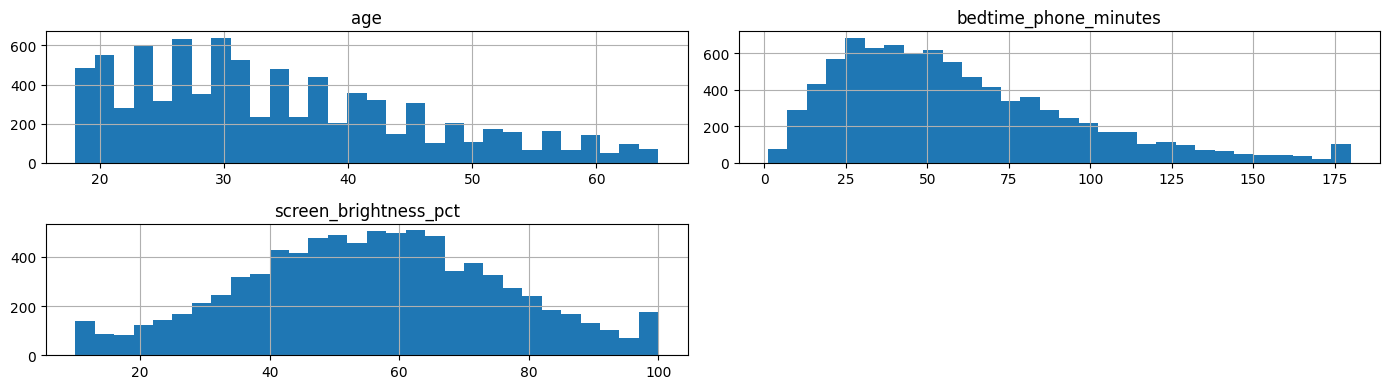

In [41]:
df[["age", "bedtime_phone_minutes", "screen_brightness_pct"]].hist(bins=30, figsize=(14, 4))
plt.tight_layout()
plt.show()

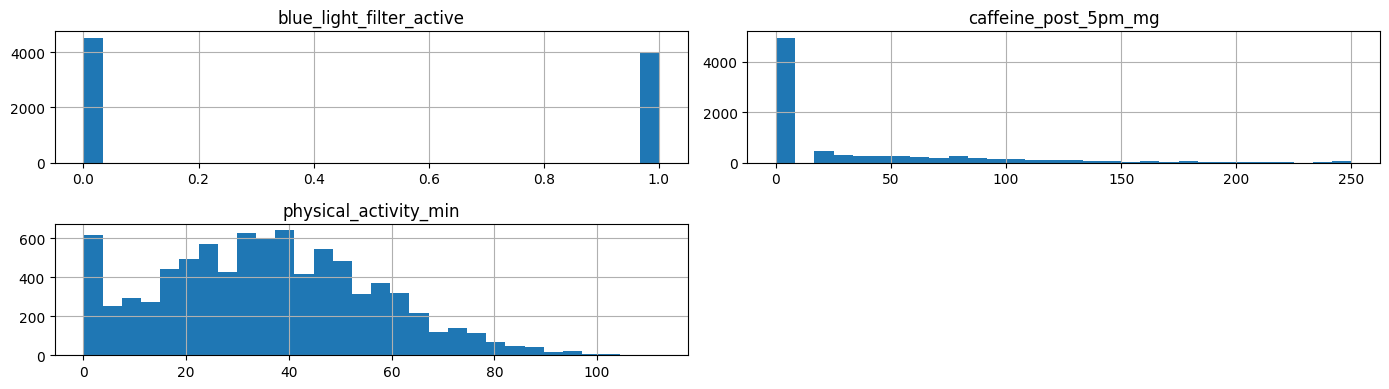

In [42]:
df[["blue_light_filter_active", "caffeine_post_5pm_mg", "physical_activity_min"]].hist(bins=30, figsize=(14, 4))
plt.tight_layout()
plt.show()

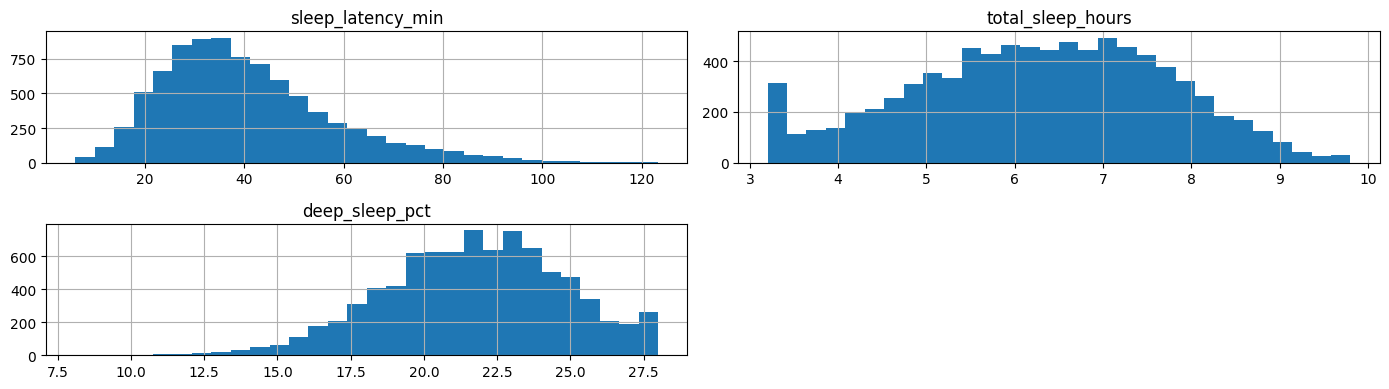

In [43]:
df[["sleep_latency_min", "total_sleep_hours", "deep_sleep_pct"]].hist(bins=30, figsize=(14, 4))
plt.tight_layout()
plt.show()

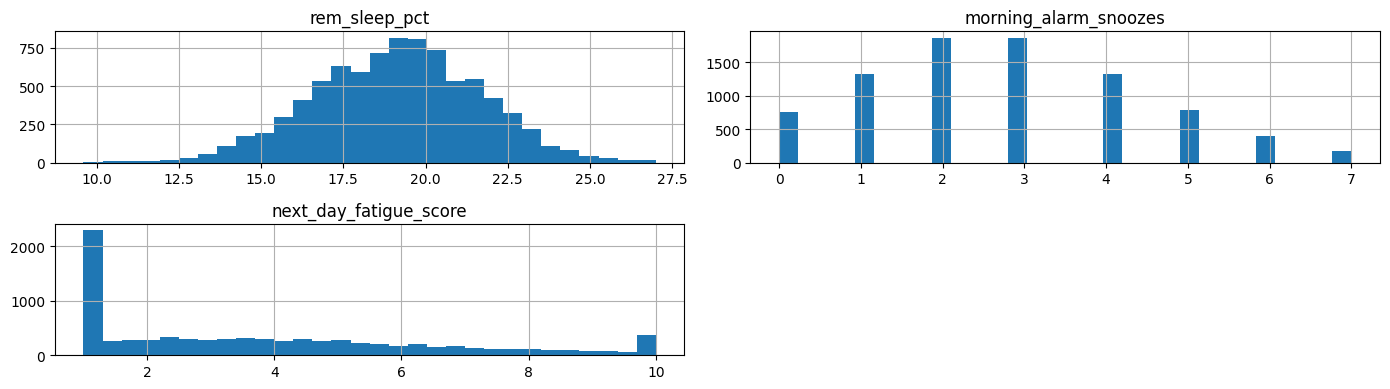

In [44]:
df[["rem_sleep_pct", "morning_alarm_snoozes", "next_day_fatigue_score"]].hist(bins=30, figsize=(14, 4))
plt.tight_layout()
plt.show()

## 2. Preprocessing
1. **Remove columns that must not be used for clustering:** `user_id` (just an identifier) and `sleep_debt_category` (the label, kept aside for evaluation).
2. **Keep numeric features only.** K-Means and PCA work with distances/variance, so text columns (gender, occupation...) are left out as the project asks for numerical features.

3. **Standardization (required):** every feature gets mean 0 and standard deviation 1. Without it, features with big numbers (like `sleep_latency_min` or `caffeine_post_5pm_mg`) would dominate features with small numbers (like `total_sleep_hours`).

In [45]:
df["sleep_debt_category"].value_counts()

,count
sleep_debt_category,
Moderate Debt,4462
Mild Deficit,2004
Optimal Recovery,1387
Severe Sleep Debt,647


In [46]:
y = df["sleep_debt_category"]

df = df.drop(columns=["user_id", "sleep_debt_category"])

In [47]:
X = df.select_dtypes(include="number")

print("Numerical features:", X.columns.tolist())
print("Shape:", X.shape)

Numerical features: ['age', 'bedtime_phone_minutes', 'screen_brightness_pct', 'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min', 'sleep_latency_min', 'total_sleep_hours', 'deep_sleep_pct', 'rem_sleep_pct', 'morning_alarm_snoozes', 'next_day_fatigue_score']
Shape: (8500, 12)


In [48]:
print(X.isnull().sum().sum())

0


In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [50]:
print("Before Scaling:")
display(X.head())

print("After Scaling:")
display(pd.DataFrame(X_scaled, columns=X.columns).head())

Before Scaling:


,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score
0,29,179,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0
1,58,163,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0
2,41,100,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0
3,36,34,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7
4,23,27,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3


After Scaling:


,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score
0,-0.462348,3.242637,-0.058132,1.06669,-0.639723,-0.706182,2.506811,-2.120223,0.574828,1.215148,2.497482,2.311113
1,2.041196,2.809383,1.050215,1.06669,1.131804,1.743602,2.638662,-1.525550,-1.217172,0.940240,2.497482,2.311113
2,0.573601,1.103444,0.193765,-0.93748,0.226785,-0.610112,1.709970,-2.120223,-1.184591,0.547515,2.497482,2.311113
3,0.141956,-0.683729,-0.158891,-0.93748,1.228083,0.638797,-0.147414,0.500487,-0.044227,1.293693,-1.041699,-0.780139
4,-0.980323,-0.873278,1.352491,1.06669,-0.639723,0.110413,-0.479909,-1.165980,0.770318,1.450783,0.727892,0.560645


In [51]:
corr = pd.DataFrame(X_scaled, columns=X.columns).corr()

display(corr.round(2))

,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score
age,1.00,-0.02,-0.01,0.00,-0.01,-0.01,-0.06,0.02,0.01,0.07,-0.03,-0.03
bedtime_phone_minutes,-0.02,1.00,0.00,0.00,-0.01,-0.01,0.86,-0.55,-0.26,-0.01,0.65,0.71
screen_brightness_pct,-0.01,0.00,1.00,0.01,0.00,0.00,0.09,-0.03,-0.15,0.00,0.05,0.09
blue_light_filter_active,0.00,0.00,0.01,1.00,-0.00,0.00,-0.06,0.04,0.11,0.00,-0.04,-0.08
caffeine_post_5pm_mg,-0.01,-0.01,0.00,-0.00,1.00,-0.00,0.20,-0.04,-0.34,-0.42,0.09,0.18
physical_activity_min,-0.01,-0.01,0.00,0.00,-0.00,1.00,-0.01,0.00,0.33,-0.00,-0.01,-0.03
sleep_latency_min,-0.06,0.86,0.09,-0.06,0.20,-0.01,1.00,-0.53,-0.33,-0.16,0.68,0.74
total_sleep_hours,0.02,-0.55,-0.03,0.04,-0.04,0.00,-0.53,1.00,0.18,0.03,-0.83,-0.88
deep_sleep_pct,0.01,-0.26,-0.15,0.11,-0.34,0.33,-0.33,0.18,1.00,0.17,-0.23,-0.34
rem_sleep_pct,0.07,-0.01,0.00,0.00,-0.42,-0.00,-0.16,0.03,0.17,1.00,-0.08,-0.11


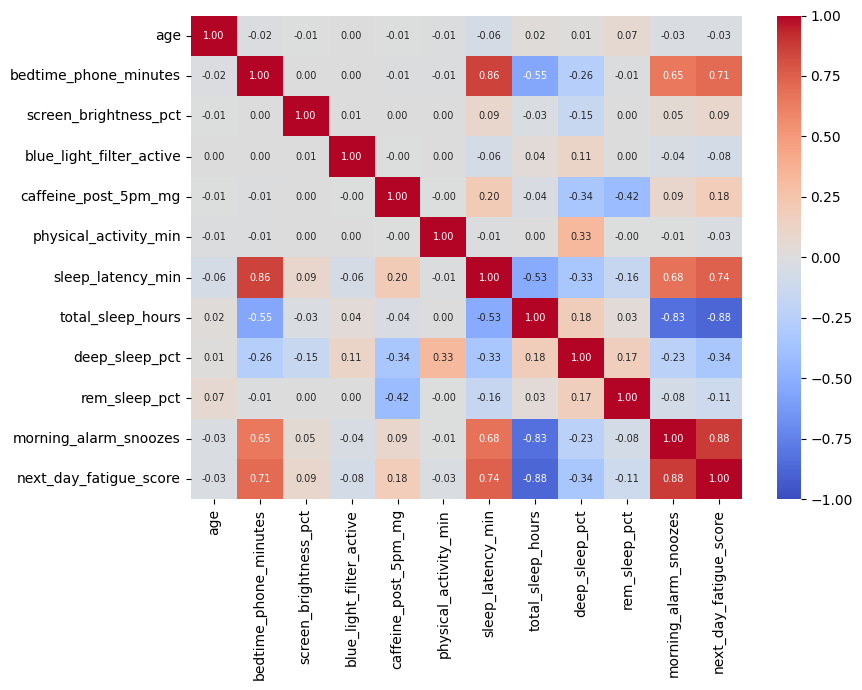

In [52]:
corr = pd.DataFrame(X_scaled, columns=X.columns).corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, annot_kws={"size": 7})

plt.tight_layout()
plt.show()

### Correlation Analysis

The correlation matrix shows several strong relationships between numerical features:

- `total_sleep_hours` and `next_day_fatigue_score`: Strong negative correlation (-0.88).
- `morning_alarm_snoozes` and `next_day_fatigue_score`: Strong positive correlation (0.88).
- `bedtime_phone_minutes` and `sleep_latency_min`: Strong positive correlation (0.86).
- `total_sleep_hours` and `morning_alarm_snoozes`: Strong negative correlation (-0.83).



## 3. Choosing the number of clusters K
We try K = 2 to 8 and look at two classic curves: the **elbow** (inertia, lower is tighter) and the **silhouette** (higher is better separated). The data have 4 sleep-debt categories, so **K = 4** is a natural choice and also lets us compare the clusters directly with the real categories. (You can change `K` in the first cell.)

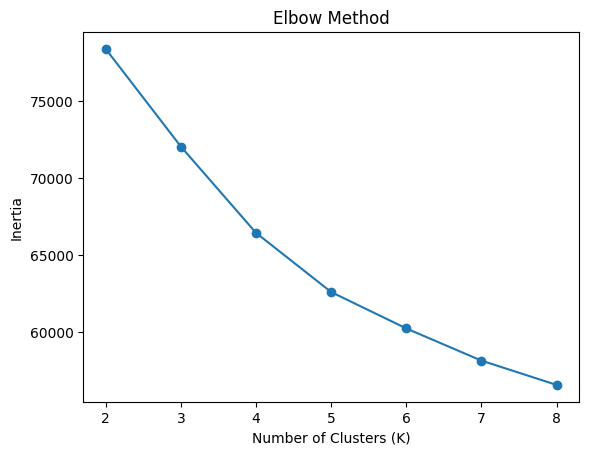

In [53]:
from sklearn.cluster import KMeans

inertia = []

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.plot(range(2, 9), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

In [54]:
for k, value in zip(range(2, 9), inertia):
    print(f"K = {k}, Inertia = {value:.2f}")

K = 2, Inertia = 78381.85
K = 3, Inertia = 72043.20
K = 4, Inertia = 66437.54
K = 5, Inertia = 62593.76
K = 6, Inertia = 60229.29
K = 7, Inertia = 58139.02
K = 8, Inertia = 56561.76


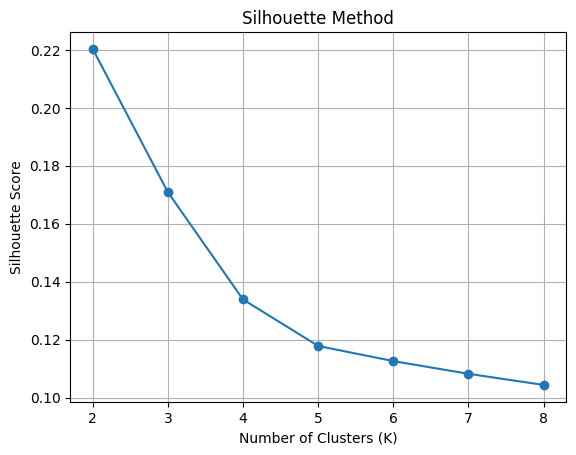

In [55]:
silhouette_scores = []

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.plot(range(2, 9), silhouette_scores, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Method")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

In [56]:
for k, score in zip(range(2, 9), silhouette_scores):
    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.2203
K = 3, Silhouette Score = 0.1709
K = 4, Silhouette Score = 0.1339
K = 5, Silhouette Score = 0.1179
K = 6, Silhouette Score = 0.1126
K = 7, Silhouette Score = 0.1083
K = 8, Silhouette Score = 0.1044


In [57]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

df['cluster'] = kmeans.fit_predict(X_scaled)

df['cluster'].value_counts()

,count
cluster,
3,3369
0,2669
2,1271
1,1191


## 5. PCA with 2 components
PCA builds new axes (components) that capture as much of the variation as possible. We keep only the first two, then check **how much variance they keep**, which features they are made of, and how many components would be needed to keep 90% of the information.

In [58]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original Data Shape:", X_scaled.shape)
print("PCA Data Shape:", X_pca.shape)
from sklearn.decomposition import PCA

Original Data Shape: (8500, 12)
PCA Data Shape: (8500, 2)


In [59]:
from sklearn.cluster import KMeans

kmeans_after = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

labels_after = kmeans_after.fit_predict(X_pca)

In [60]:
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

labels_true = LabelEncoder().fit_transform(y)
labels_before = df['cluster'].values

print("Before PCA | ARI:", round(adjusted_rand_score(labels_true, labels_before), 3),
      "| NMI:", round(normalized_mutual_info_score(labels_true, labels_before), 3))
print("After PCA | ARI:", round(adjusted_rand_score(labels_true, labels_after), 3),
      "| NMI:", round(normalized_mutual_info_score(labels_true, labels_after), 3))
print("Variance kept by the 2 PCA components:", round(pca.explained_variance_ratio_.sum() * 100, 2)
)

Before PCA | ARI: 0.22 | NMI: 0.324
After PCA | ARI: 0.187 | NMI: 0.305
Variance kept by the 2 PCA components: 47.61


## 7. Visualization: before vs after PCA


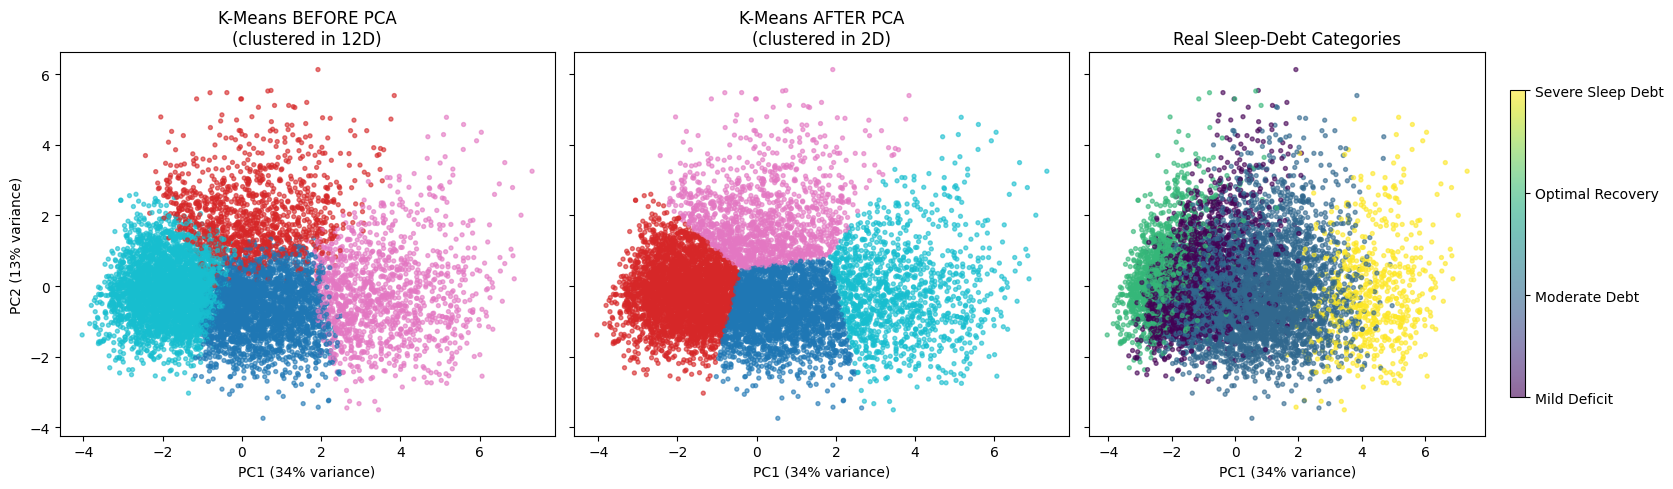

In [61]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# Before PCA clusters
labels_before = df['cluster'].values

# Real sleep-debt categories
le = LabelEncoder()
labels_true = le.fit_transform(y)

# Explained variance
var_ratio = pca.explained_variance_ratio_

# Create 3 plots side by side
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)

# Left: Clustering BEFORE PCA
axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels_before,
    cmap="tab10",
    s=8,
    alpha=0.6
)

# Middle: Clustering AFTER PCA
axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels_after,
    cmap="tab10",
    s=8,
    alpha=0.6
)

# Right: Real categories
points = axes[2].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels_true,
    cmap="viridis",
    s=8,
    alpha=0.6
)

axes[0].set_title("K-Means BEFORE PCA\n(clustered in 12D)")
axes[1].set_title("K-Means AFTER PCA\n(clustered in 2D)")
axes[2].set_title("Real Sleep-Debt Categories")

# Axis labels
for ax in axes:
    ax.set_xlabel(f"PC1 ({var_ratio[0]:.0%} variance)")

axes[0].set_ylabel(f"PC2 ({var_ratio[1]:.0%} variance)")

colorbar = fig.colorbar(points, ax=axes[2], shrink=0.8)
colorbar.set_ticks(range(len(le.classes_)))
colorbar.set_ticklabels(le.classes_)

plt.tight_layout()
plt.show()

# Analysis

## 1. How did PCA affect clustering results?

PCA changed the clustering results because K-Means was applied to only two principal components instead of the original 12 features. The cluster assignments and cluster sizes changed after dimensionality reduction. The ARI score decreased from 0.220 to 0.187, indicating that clustering after PCA was slightly less aligned with the real categories.

## 2. Did visualization become clearer?

Yes, PCA made it easier to visualize the data in two dimensions using PC1 and PC2. However, the two components retained only 47.61% of the total variance, so the visualization does not represent all the information in the original dataset. Therefore, easier visualization does not necessarily mean better-separated clusters.

## 3. Did you lose important information?

Yes. PCA reduced the data from 12 features to 2 principal components, which retained only 47.61% of the total variance. This means that 52.39% of the variance was not represented in the two components. Therefore, some information was lost during dimensionality reduction.

## 4. Which approach is better and why?

Clustering before PCA performed slightly better in this experiment. Its ARI score was 0.220 compared to 0.187 after PCA, and its NMI score was 0.324 compared to 0.305 after PCA. This suggests that using the original 12 features preserved more useful information for clustering. Therefore, K-Means before PCA was the better approach for this dataset, while PCA was useful for visualization and dimensionality reduction.

# Bonus (Optional)

## 1. Experiment with Different Number of PCA Components

In this experiment, PCA was applied using 3 components instead of 2 to examine how increasing the number of components affects explained variance and clustering performance.

In [62]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

pca_3 = PCA(n_components=3)
X_pca_3 = pca_3.fit_transform(X_scaled)


kmeans_3 = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_3 = kmeans_3.fit_predict(X_pca_3)

# Evaluate results
print("Number of Components: 3")
print("Explained Variance:", round(pca_3.explained_variance_ratio_.sum() * 100, 2), "%")
print("ARI:", round(adjusted_rand_score(labels_true, labels_3), 4))
print("NMI:", round(normalized_mutual_info_score(labels_true, labels_3), 4))

Number of Components: 3
Explained Variance: 57.57 %
ARI: 0.1935
NMI: 0.3072


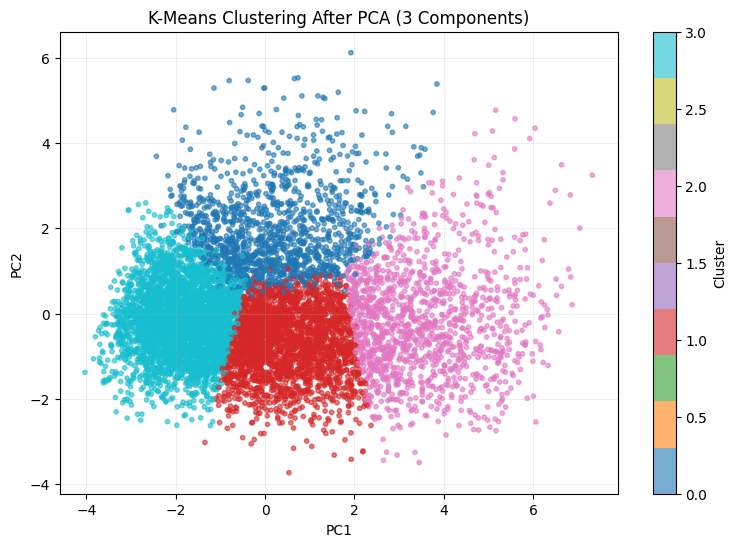

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca_3[:, 0],
    X_pca_3[:, 1],
    c=labels_3,
    cmap="tab10",
    s=10,
    alpha=0.6
)

plt.title("K-Means Clustering After PCA (3 Components)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label="Cluster")
plt.grid(alpha=0.2)
plt.show()

## 2. Compare Clustering Results Using Another Algorithm (DBSCAN)

In this experiment, DBSCAN was applied as an alternative clustering algorithm to compare its results with K-Means. Unlike K-Means, DBSCAN groups data points based on density and can identify noise points.

In [64]:
dbscan = DBSCAN(eps=0.2, min_samples=10)

labels_dbscan = dbscan.fit_predict(X_pca)

print("Number of Clusters:",
      len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0))

print("Noise Points:", sum(labels_dbscan == -1))

print("ARI:", round(adjusted_rand_score(labels_true, labels_dbscan), 4))
print("NMI:", round(normalized_mutual_info_score(labels_true, labels_dbscan), 4))

Number of Clusters: 7
Noise Points: 682
ARI: 0.0706
NMI: 0.0907


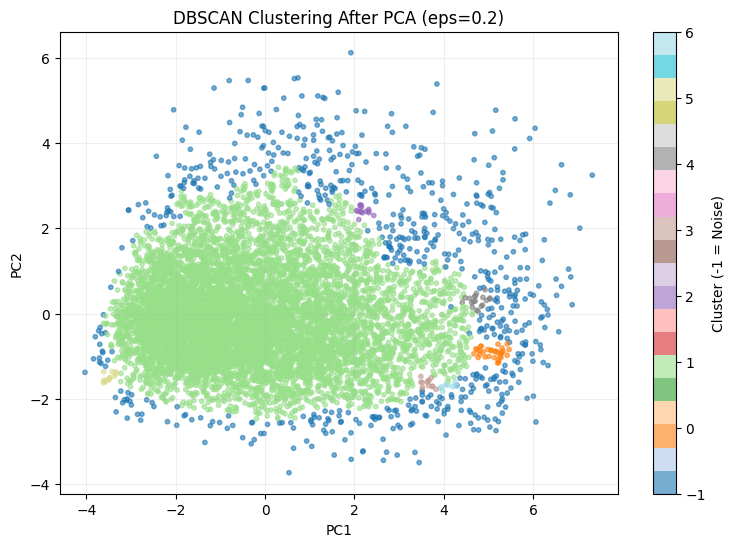

In [65]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_dbscan,
    cmap="tab20",
    s=10,
    alpha=0.6
)

plt.title("DBSCAN Clustering After PCA (eps=0.2)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label="Cluster (-1 = Noise)")
plt.grid(alpha=0.2)
plt.show()

# Key Insights (Final Summary)

1. All 12 numeric features were standardized before applying K-Means and PCA, ensuring that features with larger scales did not dominate the analysis.

2. PCA with 2 components retained **47.61% of the total variance**, while **52.39% was not represented** in the two components.

3. K-Means **before PCA** matched the real categories slightly better, achieving an ARI of **0.220** and an NMI of **0.324**, compared to an ARI of **0.187** and an NMI of **0.305** after PCA.

4. PCA made it easier to **visualize the data in 2D** using PC1 and PC2. However, easier visualization did not necessarily result in better-separated clusters.

5. Using **3 PCA components** retained **57.57% of the total variance**. The clustering results changed slightly, with an ARI of **0.1935** and an NMI of **0.3072**. This shows that increasing the number of components preserved more variance but did not improve clustering performance compared to using the original features.

6. **DBSCAN** with eps = 0.2 identified 7 clusters and 682 noise points. However, its scores were relatively low (ARI = **0.0706**, NMI = **0.0907**), indicating that it did not match the actual sleep-debt categories well.

7. **Final Conclusion:** PCA was useful for visualization and dimensionality reduction, but K-Means applied to the original standardized features achieved the best clustering results for this dataset.